# **Field Detector**

This notebook marks every scoring field on the board inside the inner ring.

The idea is to unroll the board. In the unrolled image the fields form a grid:

Horizontal lines: The 20 sector boundaries.

Vertical lines: The rings (bull, treble and double).

So we find the lines in the unrolled image, where it is easy, and then map each field back onto the real image.

It uses the board functions from `board_functions.py` to find the bullseye and the two ellipses. These are the same functions as in `board_detector.ipynb`.

## Steps

1. Load the board.
2. Unroll the board.
3. Find the horizontal lines (sectors).
4. Find the vertical lines (rings).
5. Name the sectors.
6. Mark every field.
7. Check the results.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

from board_functions import calibrate_from_video, crop_around

plt.rcParams["figure.dpi"] = 72   # keeps the notebook file small

## **Settings and helper functions**

In [2]:
VIDEO_DIR = Path("../data/videos")
FIGURE_DIR = Path("../reports/figures")

N_ROWS = 720           # one row per 0.5 degrees around the board
N_COLUMNS = 800        # columns from the bullseye (0.0) to the inner ring (1.0)
N_SECTORS = 20
ROWS_PER_SECTOR = N_ROWS // N_SECTORS

# The sector numbers clockwise, starting from the top of a dartboard
SECTOR_NUMBERS = [20, 1, 18, 4, 13, 6, 10, 15, 2, 17, 3, 19, 7, 16, 8, 11, 14, 9, 12, 5]

In [3]:
def to_column(fraction):
    """Converts a position from 0.0 (bullseye) to 1.0 (inner ring) to a column number."""
    return int(round(fraction * (N_COLUMNS - 1)))

## **Step 1: Load the board**

`calibrate_from_video` makes the clean median image of a video (without people or noise) and finds the bullseye and the two ellipses. Here we run it on every video.

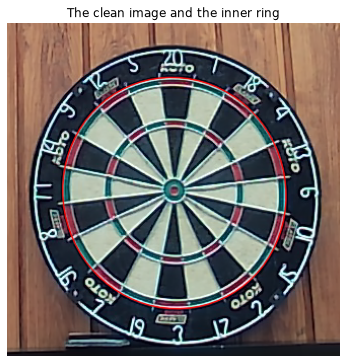

In [4]:
boards = {video.stem: calibrate_from_video(video) for video in sorted(VIDEO_DIR.glob("*.mp4"))}

example_name = "wood_background_noHuman"
board = boards[example_name]
image = board["image"]

drawn = image.copy()
cv2.ellipse(drawn, board["inner"], (0, 0, 255), 1, cv2.LINE_AA)

half_size = int(0.72 * max(board["inner"][1]))
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(crop_around(drawn, board["bullseye"], half_size), cv2.COLOR_BGR2RGB))
plt.title("The clean image and the inner ring")
plt.axis("off")
plt.show()

## **Step 2: Unroll the board**

This is the same idea as in `board_detector.ipynb`, but now column 1.0 is the inner ring and column 0.0 is the bullseye:

* each row is one direction, clockwise, with 0.5 degrees between rows,
* each column is the position between the bullseye and the inner ring.

The rings become vertical lines and the sector boundaries become horizontal lines, and the tilt of the camera is removed.

Rows are counted so that row 0 is 9 degrees to the left of straight up. On a board that hangs straight, the top sector then fills the first 36 rows.

In [5]:
def unroll_board(image, board):
    """
    Samples the image on a grid of rows (directions) and columns (positions out to the inner ring).

    Returns the unrolled image, and map_x and map_y, which say where each grid position
    is in the original image. We need those to go back to the image in step 6.
    """
    (ex, ey), (width, height), angle = board["inner"]
    bx, by = board["bullseye"]
    a = np.radians(angle)

    # Table of all combinations of position s and direction t. Direction 0 is straight up,
    # and directions grow clockwise, because y points down in an image.
    s, t = np.meshgrid(np.linspace(0, 1, N_COLUMNS), np.radians(np.arange(N_ROWS) * 360 / N_ROWS - 9))

    # Convert the direction to the angle around the ellipse, measured from its own axis
    p = t - np.pi / 2 - a

    # The centre moves from the bullseye (s = 0) to the centre of the inner ellipse (s = 1),
    # because perspective shifts the centre of a circle more the larger the circle is
    cx = bx + s**2 * (ex - bx)
    cy = by + s**2 * (ey - by)

    # Point on an ellipse: half-axes * (cos p, sin p), rotated by the ellipse angle,
    # scaled by s and moved to the centre (cx, cy)
    map_x = (cx + s * (width / 2 * np.cos(p) * np.cos(a) - height / 2 * np.sin(p) * np.sin(a))).astype(np.float32)
    map_y = (cy + s * (width / 2 * np.cos(p) * np.sin(a) + height / 2 * np.sin(p) * np.cos(a))).astype(np.float32)

    # remap reads the image at all these positions
    return cv2.remap(image, map_x, map_y, cv2.INTER_LINEAR), map_x, map_y

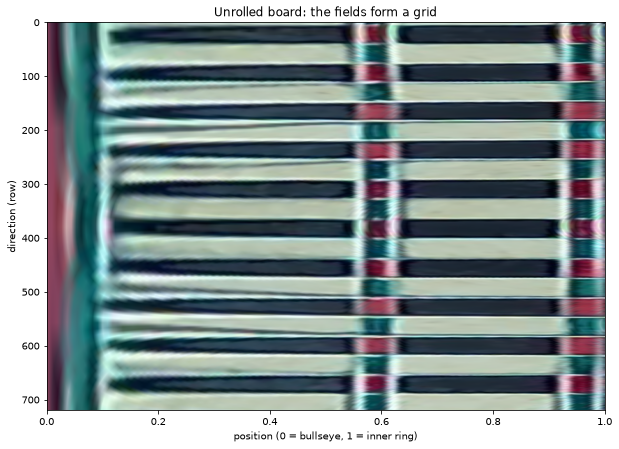

In [6]:
unrolled, map_x, map_y = unroll_board(image, board)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
plt.xlabel("position (0 = bullseye, 1 = inner ring)")
plt.ylabel("direction (row)")
plt.title("Unrolled board: the fields form a grid")
plt.show()

## **Step 3: Find the horizontal lines (sectors)**

A sector boundary is a change from dark to bright (or bright to dark) as we move up or down in the unrolled image.

1. Sobel in the row direction gives the size of that change for every pixel.
2. Averaging each row over the two single areas gives a profile with one peak per boundary. The rings and the bull are left out, because they have other patterns.
3. There are 20 boundaries about 36 rows apart. We try each possible starting row and keep the one where a "comb" of 20 evenly spaced teeth hits the most signal.
4. Each tooth then moves to the highest peak within 8 rows. The boundaries do not have to be exactly evenly spaced, because the fit to the ellipse is only an approximation of the perspective.
5. Correct the bias. The strongest change is between the black and the bright wire, so each line lands on the dark side of its wire, and dark sectors look narrower than bright ones. All sectors on a dartboard have the same size, so the difference between every second sector tells us how far to move the lines.

In [7]:
def boundary_profile(gray):
    """Returns how strongly each row looks like a sector boundary."""
    # Blur along the columns and slightly along the rows, then take the slope along the rows
    slope = np.abs(cv2.Sobel(cv2.blur(gray, (5, 3)), cv2.CV_32F, 0, 1, ksize=5))

    # Average over the two single areas, the parts of the board with a clean pattern
    inner_single = slope[:, to_column(0.15):to_column(0.55)].mean(axis=1)
    outer_single = slope[:, to_column(0.65):to_column(0.90)].mean(axis=1)
    return inner_single + outer_single


def find_sector_rows(profile, search=8):
    """Returns the 20 rows of the sector boundaries, sorted from low to high."""
    # Comb: for each starting row, add up the profile at 20 evenly spaced rows
    teeth = ROWS_PER_SECTOR * np.arange(N_SECTORS)
    comb_score = [profile[(start + teeth) % N_ROWS].sum() for start in range(ROWS_PER_SECTOR)]
    best_start = int(np.argmax(comb_score))

    # Move each tooth to the highest peak close to it.
    # % N_ROWS wraps around, because row 720 is the same direction as row 0.
    rows = []
    for tooth in best_start + teeth:
        window = np.arange(tooth - search, tooth + search + 1) % N_ROWS
        rows.append(int(window[np.argmax(profile[window])]))

    return np.sort(rows)


def equalise_sectors(rows):
    """Moves the boundaries so that every second sector has the same average width as the others."""
    # Width of each sector. rows[0] + N_ROWS closes the circle.
    widths = np.diff(np.r_[rows, rows[0] + N_ROWS])

    # Sectors alternate between dark and bright, so compare every second sector. Moving all
    # boundaries by `shift` changes the difference by 4 * shift (2 * shift for each type of sector).
    shift = (widths[0::2].mean() - widths[1::2].mean()) / 4

    # Even boundaries start the even sectors, so moving them forward and the
    # odd boundaries backward makes the even sectors narrower
    moved = rows.astype(np.float64)
    moved[0::2] += shift
    moved[1::2] -= shift

    return np.sort(np.round(moved).astype(int) % N_ROWS)

Rows between the boundaries: smallest 34 largest 38


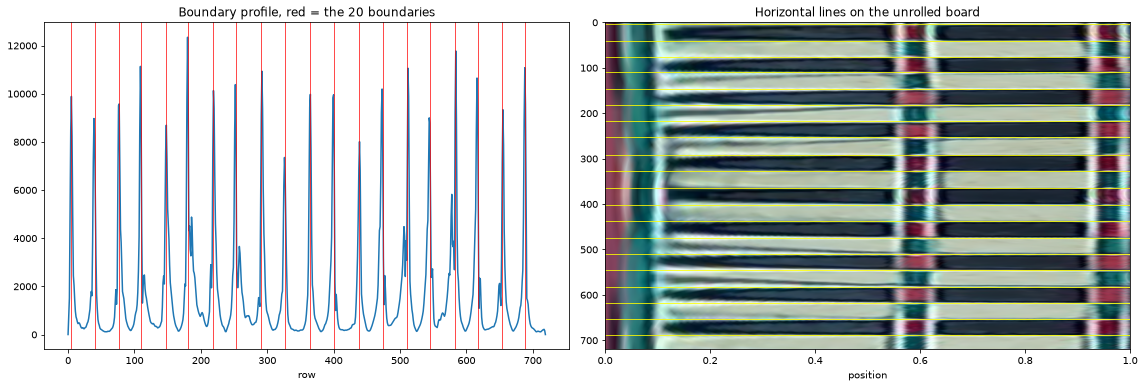

In [8]:
gray = cv2.cvtColor(unrolled, cv2.COLOR_BGR2GRAY).astype(np.float32)
profile = boundary_profile(gray)
sector_rows = equalise_sectors(find_sector_rows(profile))
print("Rows between the boundaries: smallest", np.diff(sector_rows).min(), "largest", np.diff(sector_rows).max())

fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
axs[0].plot(profile)
for row in sector_rows:
    axs[0].axvline(row, color="r", linewidth=0.7)
axs[0].set_xlabel("row")
axs[0].set_title("Boundary profile, red = the 20 boundaries")

axs[1].imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
for row in sector_rows:
    axs[1].axhline(row, color="yellow", linewidth=0.8)
axs[1].set_xlabel("position")
axs[1].set_title("Horizontal lines on the unrolled board")
plt.tight_layout()
plt.show()

## **Step 4: Find the vertical lines (rings)**

The rings are separated by thin bright **wires**, which are vertical lines in the unrolled image.

1. The **top-hat** (image minus opening, L02) keeps thin bright lines, as in `board_detector.ipynb`. The structuring element is 15 columns wide.
2. The **median of each column** ignores anything that is only present in some rows, and keeps what goes all the way round.
3. Each ring is the highest peak close to where it normally sits. These starting positions are rough values, so the ring positions are measured on the board and not fixed.

The outer edge of the double ring needs no search, because it is the inner ellipse itself (position 1.0).

In [9]:
# Rough position of each ring, as a fraction of the distance out to the inner ring
RING_GUESSES = dict(bull=0.04, outer_bull=0.10, treble_inner=0.56, treble_outer=0.62, double_inner=0.93)


def find_rings(gray, search=0.03):
    """Returns the measured position of each ring and the profile they were found in."""
    # Top-hat along the columns: only thin bright lines are left
    opened = cv2.morphologyEx(gray, cv2.MORPH_OPEN, np.ones((1, 15), np.uint8))

    # The median over all directions keeps what goes all the way round the board
    wire_profile = np.median(gray - opened, axis=0)

    rings = {}
    for name, guess in RING_GUESSES.items():
        window = np.arange(to_column(guess - search), to_column(guess + search) + 1)
        rings[name] = float(window[np.argmax(wire_profile[window])] / (N_COLUMNS - 1))

    rings["double_outer"] = 1.0
    return rings, wire_profile

{'bull': 0.043, 'outer_bull': 0.104, 'treble_inner': 0.561, 'treble_outer': 0.621, 'double_inner': 0.929, 'double_outer': 1.0}


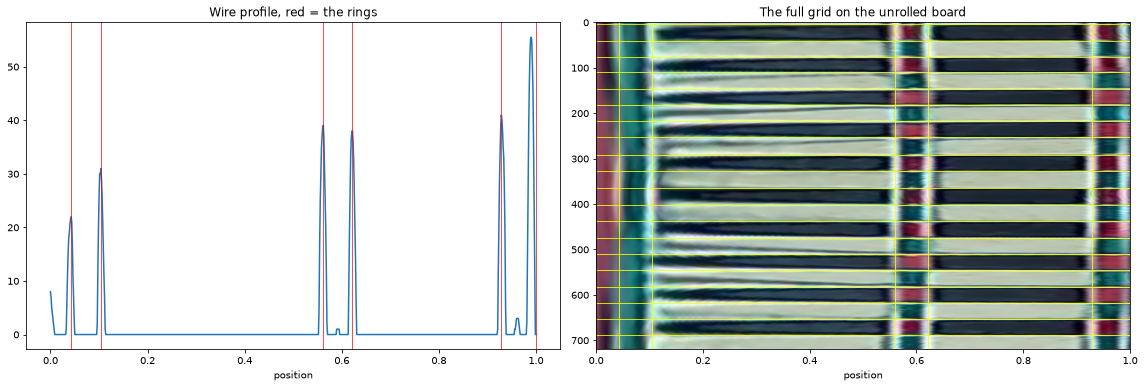

In [10]:
rings, wire_profile = find_rings(gray)
print({name: round(value, 3) for name, value in rings.items()})

positions = np.linspace(0, 1, N_COLUMNS)
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
axs[0].plot(positions, wire_profile)
for value in rings.values():
    axs[0].axvline(value, color="r", linewidth=0.7)
axs[0].set_xlabel("position")
axs[0].set_title("Wire profile, red = the rings")

axs[1].imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
for row in sector_rows:
    axs[1].axhline(row, color="yellow", linewidth=0.8)
for value in rings.values():
    axs[1].axvline(value, color="yellow", linewidth=0.8)
axs[1].set_xlabel("position")
axs[1].set_title("The full grid on the unrolled board")
plt.tight_layout()
plt.show()

## **Step 5: Name the sectors**

The grid does not tell us which sector is which. We need to find sector 20, and the rest then follow clockwise in the fixed order of a dartboard.

The sectors alternate between dark and bright, and sector 20 is **dark**. So we take the dark sector closest to straight up.

This assumes that the board hangs with 20 roughly at the top (within about 18 degrees). We do not read the numbers themselves.

In [11]:
def name_sectors(gray, sector_rows):
    """
    Finds which sector is 20.

    Returns a list with one (number, first row, last row) for each sector, and the
    brightness of the sectors, in the order they are found in the unrolled image.
    """
    # Sector i goes from boundary i to boundary i + 1. % N_ROWS wraps around for the last one.
    starts = sector_rows
    stops = np.roll(sector_rows, -1)

    # Brightness of each sector, measured in the outer single area
    # (a few rows are skipped at each end to stay away from the boundaries)
    outer_single = gray[:, to_column(0.65):to_column(0.90)]
    brightness = []
    for start, stop in zip(starts, stops):
        rows = np.arange(start + 6, start + (stop - start) % N_ROWS - 6) % N_ROWS
        brightness.append(outer_single[rows].mean())
    brightness = np.array(brightness)

    # The middle row of each sector, as the distance in rows from straight up (row 18)
    middles = starts + ((stops - starts) % N_ROWS) / 2
    distance_to_top = np.abs((middles - 18 + N_ROWS / 2) % N_ROWS - N_ROWS / 2)

    # Sector 20 is the dark sector that is closest to the top
    dark = brightness < np.median(brightness)
    first = int(np.argmin(np.where(dark, distance_to_top, np.inf)))

    # Sectors go clockwise, which is the direction of increasing rows
    sectors = []
    for k, number in enumerate(SECTOR_NUMBERS):
        i = (first + k) % N_SECTORS
        sectors.append((number, int(starts[i]), int(stops[i])))

    return sectors, brightness

number, first row, last row: [(20, 4, 40), (1, 40, 76), (18, 76, 110), (4, 110, 147)] ...


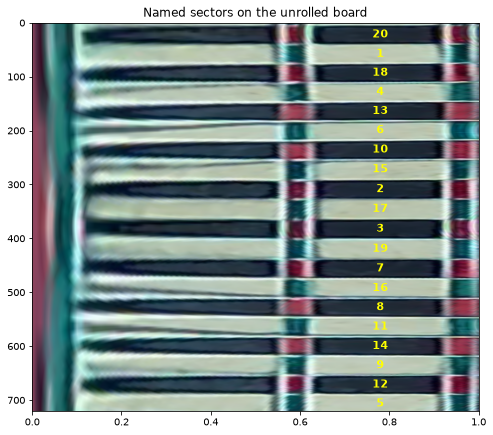

In [12]:
sectors, brightness = name_sectors(gray, sector_rows)
print("number, first row, last row:", sectors[:4], "...")

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cv2.cvtColor(unrolled, cv2.COLOR_BGR2RGB), aspect="auto", extent=[0, 1, N_ROWS, 0])
for number, start, stop in sectors:
    middle = (start + ((stop - start) % N_ROWS) / 2) % N_ROWS
    ax.text(0.78, middle, str(number), color="yellow", fontsize=11, weight="bold", ha="center", va="center")
ax.set_title("Named sectors on the unrolled board")
plt.show()

## **Step 6: Mark every field**

Each field is now a rectangle in the unrolled grid. `map_x` and `map_y` tell us where each grid position is in the real image, so we walk around the rectangle and get the outline of the field as a polygon.

This gives **82 fields**: 20 sectors with 4 fields each (inner single, treble, outer single, double), plus the outer bull and the bull.

We fill the polygons into a **field map**, an image with the same size as the video frame where each pixel holds the number of its field (-1 outside the fields). Scoring a dart later only means reading one pixel of this map.

In [13]:
def rows_between(start, stop):
    """Returns the rows from start to stop, also when they wrap around past row 720."""
    return np.arange(start, start + (stop - start) % N_ROWS + 1) % N_ROWS


def field_outline(map_x, map_y, start, stop, position_inner, position_outer):
    """Returns the outline of one grid rectangle as a polygon in the real image."""
    rows = rows_between(start, stop)
    inner, outer = to_column(position_inner), to_column(position_outer)

    # Walk out along the outer edge, then back along the inner edge
    x = np.r_[map_x[rows, outer], map_x[rows[::-1], inner]]
    y = np.r_[map_y[rows, outer], map_y[rows[::-1], inner]]
    return np.round(np.column_stack([x, y])).astype(np.int32)


def build_fields(sectors, rings, map_x, map_y):
    """Returns one entry with name, score and outline for each of the 82 fields."""
    fields = []

    for number, start, stop in sectors:
        # (name, score, position of the inner edge, position of the outer edge)
        parts = [(f"S{number} inner", number, rings["outer_bull"], rings["treble_inner"]),
                 (f"T{number}", 3 * number, rings["treble_inner"], rings["treble_outer"]),
                 (f"S{number} outer", number, rings["treble_outer"], rings["double_inner"]),
                 (f"D{number}", 2 * number, rings["double_inner"], rings["double_outer"])]

        for name, score, inner, outer in parts:
            fields.append(dict(name=name, score=score,
                               outline=field_outline(map_x, map_y, start, stop, inner, outer)))

    # The bulls are full circles, so they have only one edge
    for name, score, ring in [("Outer bull", 25, "outer_bull"), ("Bull", 50, "bull")]:
        circle = np.column_stack([map_x[:, to_column(rings[ring])], map_y[:, to_column(rings[ring])]])
        fields.append(dict(name=name, score=score, outline=np.round(circle).astype(np.int32)))

    return fields


def build_field_map(fields, image_shape):
    """Returns an image where each pixel holds the number of its field (-1 = no field)."""
    field_map = np.full(image_shape[:2], -1, np.int16)

    # The bull comes after the outer bull in the list, so it is painted on top of it
    for number, field in enumerate(fields):
        cv2.fillPoly(field_map, [field["outline"]], number)

    return field_map

In [14]:
def draw_fields(image, fields, field_map):
    """Returns the image with every field coloured and outlined."""
    # Each field gets a colour from its number, so that neighbouring fields differ
    rng = np.random.default_rng(0)
    colours = rng.integers(60, 255, size=(len(fields), 3), dtype=np.uint8)

    # Blend the colours with the image, only for pixels that belong to a field
    coloured = image.copy()
    inside = field_map >= 0
    coloured[inside] = colours[field_map[inside]]
    output = cv2.addWeighted(image, 0.55, coloured, 0.45, 0)

    for field in fields:
        cv2.polylines(output, [field["outline"]], True, (255, 255, 255), 1, cv2.LINE_AA)

    return output

82 fields


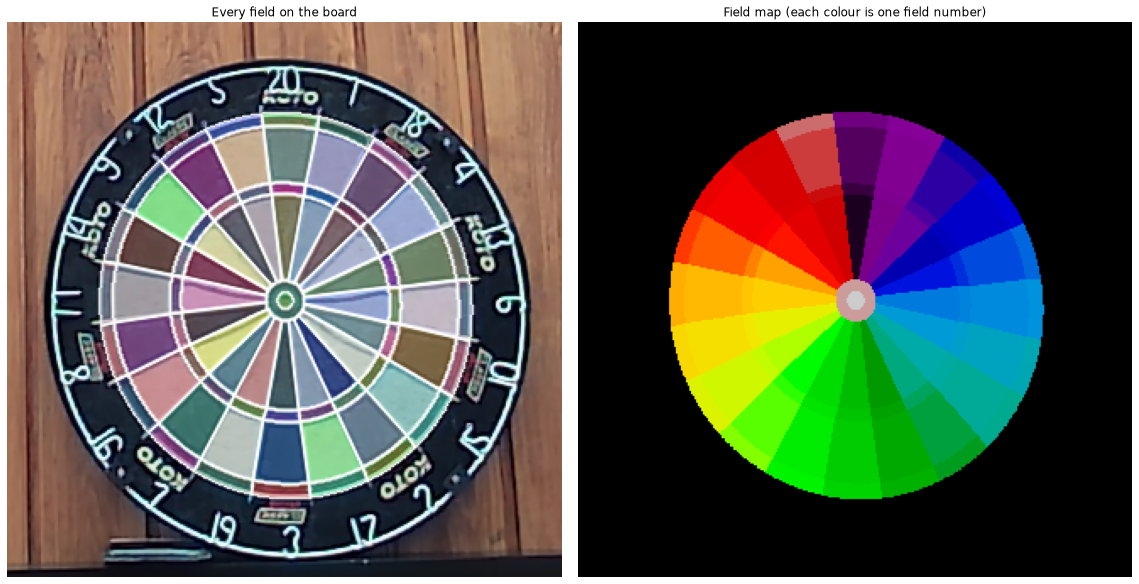

In [15]:
fields = build_fields(sectors, rings, map_x, map_y)
field_map = build_field_map(fields, image.shape)
print(len(fields), "fields")

fig, axs = plt.subplots(1, 2, figsize=(16, 8))
marked = draw_fields(image, fields, field_map)
axs[0].imshow(cv2.cvtColor(crop_around(marked, board["bullseye"], half_size), cv2.COLOR_BGR2RGB))
axs[0].set_title("Every field on the board")
axs[0].axis("off")

axs[1].imshow(crop_around(field_map.astype(np.float32) + 1, board["bullseye"], half_size), cmap="nipy_spectral")
axs[1].set_title("Field map (each colour is one field number)")
axs[1].axis("off")
plt.tight_layout()
plt.show()

Reading the map works like this. Later the pixel will come from the dart tip.

In [16]:
def field_at(x, y, fields, field_map):
    """Returns the name and score at a pixel in the image."""
    number = field_map[int(y), int(x)]
    if number < 0:
        return "Miss", 0
    return fields[number]["name"], fields[number]["score"]


# Example: a point on the top sector, halfway between the treble ring and the inner ring
column = to_column((rings["treble_outer"] + rings["double_inner"]) / 2)
row = sectors[0][1] + 18
x, y = map_x[row, column], map_y[row, column]
print(f"Pixel ({x:.0f}, {y:.0f}):", field_at(x, y, fields, field_map))

Pixel (1034, 724): ('S20 outer', 20)


## **Step 7: Check the results**

`detect_fields` runs steps 2–6 on one board, and we run it on every video.

We do not have hand-marked ground truth yet, but we can test the results against what we know about a dartboard:

* **Alternating sectors:** the 20 sectors must alternate between dark and bright all the way round.
* **All fields present:** all 82 fields must be visible in the field map. Otherwise a field was painted over or lost.
* **Same rings everywhere:** all videos show the same board, so each ring must be at the same position in every video.

In [17]:
def detect_fields(image, board):
    """Runs steps 2-6 on one image and returns everything that was found."""
    unrolled, map_x, map_y = unroll_board(image, board)                     # step 2
    gray = cv2.cvtColor(unrolled, cv2.COLOR_BGR2GRAY).astype(np.float32)

    sector_rows = equalise_sectors(find_sector_rows(boundary_profile(gray)))   # step 3
    rings, _ = find_rings(gray)                                             # step 4
    sectors, brightness = name_sectors(gray, sector_rows)                   # step 5
    fields = build_fields(sectors, rings, map_x, map_y)                     # step 6
    field_map = build_field_map(fields, image.shape)

    return dict(image=image, sector_rows=sector_rows, rings=rings, sectors=sectors,
                brightness=brightness, fields=fields, field_map=field_map)

In [18]:
results = {name: detect_fields(b["image"], b) for name, b in boards.items()}

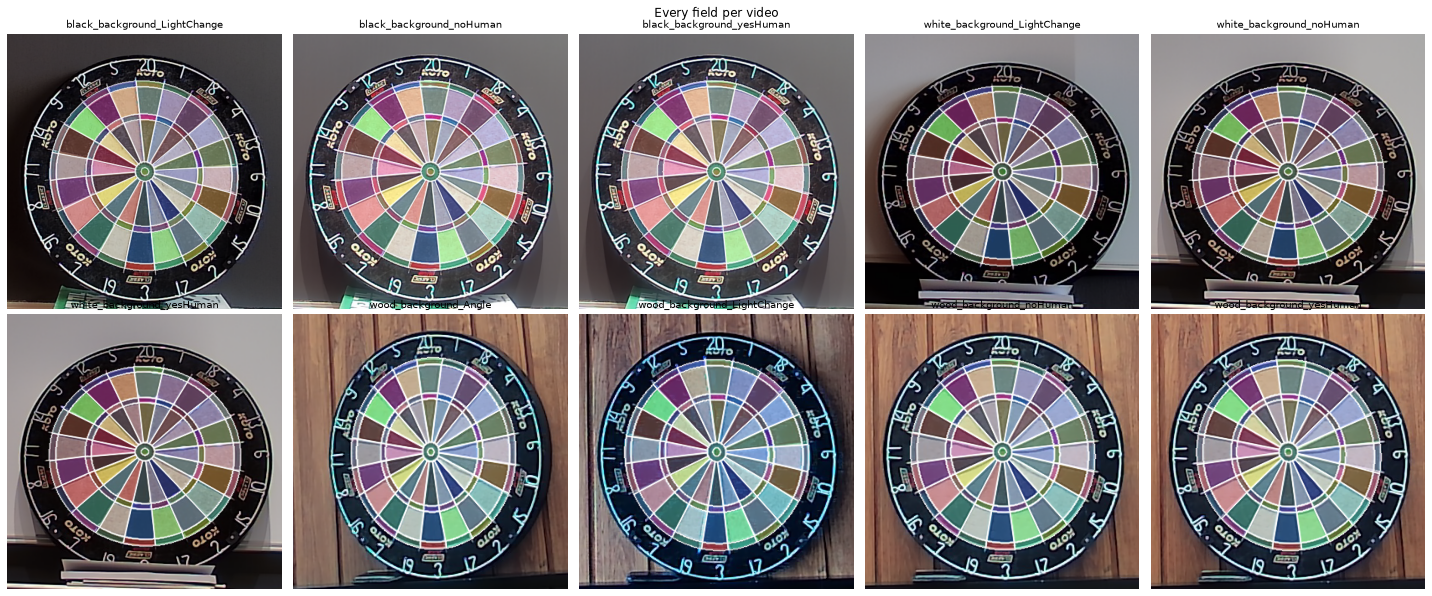

In [19]:
fig, axs = plt.subplots(2, 5, figsize=(20, 8.4))

for ax, (name, r) in zip(axs.ravel(), results.items()):
    half_size = int(0.72 * max(boards[name]["inner"][1]))
    output = crop_around(draw_fields(r["image"], r["fields"], r["field_map"]), boards[name]["bullseye"], half_size)
    ax.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=10)
    ax.axis("off")

plt.suptitle("Every field per video")
plt.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIGURE_DIR / "field_detection_all_videos.png", dpi=150)
plt.show()

In [20]:
print(f"{'video':32s} {'alternating':>12s} {'fields':>7s} {'top sector':>11s} {'smallest/largest gap [rows]':>28s}")

for name, r in results.items():
    # True if the brightness goes up and down at every step round the board
    dark = r["brightness"] < np.median(r["brightness"])
    alternating = np.all(dark != np.roll(dark, 1))

    fields_found = len(np.unique(r["field_map"][r["field_map"] >= 0]))
    gaps = np.diff(np.r_[r["sector_rows"], r["sector_rows"][0] + N_ROWS])

    print(f"{name:32s} {str(alternating):>12s} {fields_found:7d} {r['sectors'][0][0]:11d} {gaps.min():14d} / {gaps.max()}")

print("\nRing positions over all videos:")
for ring in RING_GUESSES:
    values = [r["rings"][ring] for r in results.values()]
    print(f"{ring:14s} mean {np.mean(values):.3f}   lowest {min(values):.3f}   highest {max(values):.3f}")

video                             alternating  fields  top sector  smallest/largest gap [rows]
black_background_LightChange             True      82          20             34 / 39
black_background_noHuman                 True      82          20             33 / 39
black_background_yesHuman                True      82          20             34 / 39
white_background_LightChange             True      82          20             32 / 39
white_background_noHuman                 True      82          20             34 / 39
white_background_yesHuman                True      82          20             34 / 39
wood_background_Angle                    True      82          20             33 / 40
wood_background_LightChange              True      82          20             33 / 39
wood_background_noHuman                  True      82          20             34 / 38
wood_background_yesHuman                 True      82          20             34 / 38

Ring positions over all videos:
bull        

### Zoom on the hardest case

The angled video, zoomed in on the lines only, so we can compare them with the wires on the board.

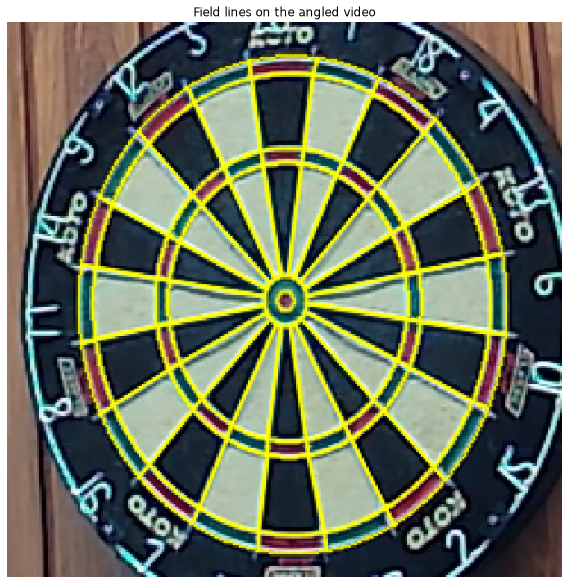

In [21]:
name = "wood_background_Angle"
r = results[name]

lines = r["image"].copy()
for field in r["fields"]:
    cv2.polylines(lines, [field["outline"]], True, (0, 255, 255), 1, cv2.LINE_AA)

half_size = int(0.56 * max(boards[name]["inner"][1]))
zoomed = cv2.resize(crop_around(lines, boards[name]["bullseye"], half_size), None, fx=2.5, fy=2.5, interpolation=cv2.INTER_NEAREST)

plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(zoomed, cv2.COLOR_BGR2RGB))
plt.title("Field lines on the angled video")
plt.axis("off")
plt.show()

## **Notes and limitations**

* **The checks are not a true accuracy measure.** For that we need hand-marked ground truth, which belongs in the evaluation part of the project.
* **Sector lines are straight rows.** The real wires are not perfectly radial in the unrolled image: over the single areas they drift by about 2 rows (1 degree) on average, and up to 7 rows at most. So a line can be a little off its wire at the inner or outer end of a sector.
* **Sector 20 must be roughly at the top.** We use dark/bright and the position, and do not read the numbers. A board rotated by more than about 18 degrees gets the wrong names.
* **Fixed sizes.** The window sizes are in unrolled rows and columns, so they do not depend on the camera, but the image detail does. A lower resolution webcam needs a new test.
* **`RING_GUESSES` are rough values from our board.** The rings are searched within 0.03 of them, so a board with very different ring positions would need new guesses.